# Olist E-Ticaret: Kategori Bazlı Aylık Talep Tahmini

**İş problemi:** Hangi ürün kategorisinin gelecek ay kaç adet satacağını tahmin etmek (stok ve sipariş planlaması için).
**Veri:** Olist (Brezilya e-ticaret) sipariş kalemleri, SQL Server `vw_OlistMasterAnalysis` view'ından çekildi.
**Yaklaşım:** Veri temizleme → kategori × ay tablosu → lag özellikleri → zamana uygun doğrulama → baseline ve ML modellerinin karşılaştırması.
**Ana bulgu:** Durağan bir dönemde en basit yöntem (geçen ayın satışı) ML modellerinden daha iyi çıktı; satışın sıçradığı aylarda ise belirgin şekilde kötüleşiyor.

In [1]:
import pandas as pd
import numpy as np
from sqlalchemy import create_engine
import warnings
warnings.filterwarnings('ignore')

SERVER_NAME='.\SQLEXPRESS'
DATABASE_NAME='OlistDB'

connection_string=f"mssql+pyodbc://@{SERVER_NAME}/{DATABASE_NAME}?driver=ODBC+Driver+17+for+SQL+Server&trusted_connection=yes"
engine= create_engine(connection_string)
df = pd.read_sql("SELECT * FROM vw_OlistMasterAnalysis", engine)



## 1. Veri Temizleme
- Fiyat ve kargo kolonları veritabanından metin geliyordu; sayıya çevrildi. `total_item_value` yan yana birleşmiş metin olduğu için `price + freight_value` ile yeniden hesaplandı.
- Tarih kolonları `datetime` tipine çevrildi.
- Boş kategori adları "bilinmiyor" olarak etiketlendi.
- İptal edilen (`canceled`) ve stokta olmayan (`unavailable`) siparişler gerçekleşmediği için çıkarıldı.

In [2]:
print(df.dtypes)

df['total_item_value'] = df['price'] + df['freight_value']

df['product_category_name'] = df['product_category_name'].str.strip().replace('', 'bilinmiyor')

print(df['order_status'].value_counts())

print(df[['price', 'freight_value', 'total_item_value']].head())

order_id                         str
customer_id                      str
customer_unique_id               str
customer_city                    str
customer_state                   str
order_status                     str
order_purchase_timestamp         str
order_approved_at                str
order_delivered_customer_date    str
order_estimated_delivery_date    str
order_item_id                    str
product_id                       str
product_category_name            str
price                            str
freight_value                    str
total_item_value                 str
dtype: object
order_status
delivered      110197
shipped          1185
canceled          542
invoiced          359
processing        357
unavailable         7
approved            3
Name: count, dtype: int64
    price freight_value total_item_value
0   58.90         13.29       58.9013.29
1  239.90         19.93      239.9019.93
2  199.00         17.87      199.0017.87
3   12.99         12.79       12.9912

In [3]:
num_cols = ['price', 'freight_value', 'order_item_id']
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

df['total_item_value'] = df['price'] + df['freight_value']

print(df[['price', 'freight_value', 'total_item_value']].head())
print(df[['price', 'freight_value', 'total_item_value']].dtypes)
print(df[['price', 'freight_value']].isna().sum())

    price  freight_value  total_item_value
0   58.90          13.29             72.19
1  239.90          19.93            259.83
2  199.00          17.87            216.87
3   12.99          12.79             25.78
4  199.90          18.14            218.04
price               float64
freight_value       float64
total_item_value    float64
dtype: object
price            0
freight_value    0
dtype: int64


In [4]:
date_cols = ['order_purchase_timestamp', 'order_approved_at',
             'order_delivered_customer_date', 'order_estimated_delivery_date']
for col in date_cols:
    df[col] = pd.to_datetime(df[col], errors='coerce')

print(df[date_cols].dtypes)

order_purchase_timestamp         datetime64[us]
order_approved_at                datetime64[us]
order_delivered_customer_date    datetime64[us]
order_estimated_delivery_date    datetime64[us]
dtype: object


## 2. Dönem Seçimi
2016-09, 2016-10, 2016-12 ve 2018-09 aylarında çok az sipariş var (5, 342, 1, 1), 2016-11 hiç yok. Bu, veri setinin o dönemlerde eksik olduğunu gösteriyor, gerçek talep düşüşü değil. Analiz **2017-01 → 2018-08** (20 ay) ile sınırlandı.

In [5]:
df_clean = df[~df['order_status'].isin(['canceled', 'unavailable'])].copy()
df_clean['order_month'] = df_clean['order_purchase_timestamp'].dt.to_period('M').dt.to_timestamp()

print(df_clean.groupby('order_month')['order_item_id'].count())

order_month
2016-09-01       5
2016-10-01     342
2016-12-01       1
2017-01-01     953
2017-02-01    1936
2017-03-01    2975
2017-04-01    2660
2017-05-01    4106
2017-06-01    3571
2017-07-01    4493
2017-08-01    4882
2017-09-01    4815
2017-10-01    5300
2017-11-01    8626
2017-12-01    6300
2018-01-01    8173
2018-02-01    7597
2018-03-01    8195
2018-04-01    7957
2018-05-01    7898
2018-06-01    7060
2018-07-01    7039
2018-08-01    7216
2018-09-01       1
Name: order_item_id, dtype: int64


In [6]:
df_clean = df_clean[(df_clean['order_month'] >= '2017-01-01') &
                    (df_clean['order_month'] <= '2018-08-01')]


## 3. Kategori × Ay Talep Tablosu
Aylık satış adedi (`sales_qty`) kategori bazında hesaplandı. Satış olmayan aylar tabloda satır olarak yer almazsa `shift` "bir önceki ay" yerine "bir önceki satırı" alır ve lag yanlış aydan gelir. Bu yüzden `pivot_table(fill_value=0)` ile tüm ay × kategori kombinasyonları oluşturuldu (20 ay × 74 kategori = 1480 satır).

In [7]:
pivot = df_clean.pivot_table(index='order_month',
                             columns='product_category_name',
                             values='order_item_id',
                             aggfunc='count',
                             fill_value=0)

monthly = pivot.reset_index().melt(id_vars='order_month',
                                   var_name='product_category_name',
                                   value_name='sales_qty')

print("Ay sayısı:", pivot.shape[0], "| Kategori sayısı:", pivot.shape[1])
print("Tablo boyutu:", monthly.shape)
monthly.head()

Ay sayısı: 20 | Kategori sayısı: 74
Tablo boyutu: (1480, 3)


,order_month,product_category_name,sales_qty
0,2017-01-01,agro_industria_e_comercio,3
1,2017-02-01,agro_industria_e_comercio,7
2,2017-03-01,agro_industria_e_comercio,2
3,2017-04-01,agro_industria_e_comercio,0
4,2017-05-01,agro_industria_e_comercio,4


## 4. Özellik Mühendisliği ve Veri Sızıntısı Kontrolü
`lag_1`, `lag_2`, `lag_3` (önceki 1-3 ayın satışı) ve `rolling_mean_3` (bu üç lag'ın ortalaması) kategori bazında üretildi. Hiçbir özellik tahmin edilen ayın kendi değerini içermiyor.

**Sızıntı kontrolü:** Ortalama, kategori bazlı lag'lardan türetildiği için bir kategori başka kategorinin verisini görmüyor. (1) İlk kategoride 2017-04 ortalaması elle doğrulandı: (2+7+3)/3 = 4.0. (2) İki kategorinin birleştiği satırlarda yeni kategorinin ilk 3 ayı NaN.

In [8]:
monthly = monthly.sort_values(['product_category_name', 'order_month']).reset_index(drop=True)

grup = monthly.groupby('product_category_name')['sales_qty']

monthly['lag_1'] = grup.shift(1)
monthly['lag_2'] = grup.shift(2)
monthly['lag_3'] = grup.shift(3)

monthly['rolling_mean_3'] = (monthly['lag_1'] + monthly['lag_2'] + monthly['lag_3']) / 3

print(monthly.head(6))

print(monthly.iloc[17:23])

  order_month      product_category_name  sales_qty  lag_1  lag_2  lag_3  \
0  2017-01-01  agro_industria_e_comercio          3    NaN    NaN    NaN   
1  2017-02-01  agro_industria_e_comercio          7    3.0    NaN    NaN   
2  2017-03-01  agro_industria_e_comercio          2    7.0    3.0    NaN   
3  2017-04-01  agro_industria_e_comercio          0    2.0    7.0    3.0   
4  2017-05-01  agro_industria_e_comercio          4    0.0    2.0    7.0   
5  2017-06-01  agro_industria_e_comercio          1    4.0    0.0    2.0   

   rolling_mean_3  
0             NaN  
1             NaN  
2             NaN  
3             4.0  
4             3.0  
5             2.0  
   order_month      product_category_name  sales_qty  lag_1  lag_2  lag_3  \
17  2018-06-01  agro_industria_e_comercio         10    8.0   12.0   28.0   
18  2018-07-01  agro_industria_e_comercio         30   10.0    8.0   12.0   
19  2018-08-01  agro_industria_e_comercio         18   30.0   10.0    8.0   
20  2017-01-01     

## 5. Mevsimsellik ve Kategori Özellikleri
`month`, `is_november` (2017-11'deki Black Friday zirvesi için) ve `category_encoded` eklendi. Lag'ların boş olduğu her kategorinin ilk 3 ayı çıkarıldı (1480 → 1258 satır).

In [9]:
from sklearn.preprocessing import LabelEncoder

monthly['month'] = monthly['order_month'].dt.month
monthly['is_november'] = (monthly['month'] == 11).astype(int)
monthly['category_encoded'] = LabelEncoder().fit_transform(monthly['product_category_name'])

df_model = monthly.dropna().reset_index(drop=True)

print("Önce:", monthly.shape, "| Sonra:", df_model.shape)
print("Ay aralığı:", df_model['order_month'].min(), "→", df_model['order_month'].max())
df_model.head()

Önce: (1480, 10) | Sonra: (1258, 10)
Ay aralığı: 2017-04-01 00:00:00 → 2018-08-01 00:00:00


,order_month,product_category_name,sales_qty,lag_1,lag_2,lag_3,rolling_mean_3,month,is_november,category_encoded
0,2017-04-01,agro_industria_e_comercio,0,2.0,7.0,3.0,4.000000,4,0,0
1,2017-05-01,agro_industria_e_comercio,4,0.0,2.0,7.0,3.000000,5,0,0
2,2017-06-01,agro_industria_e_comercio,1,4.0,0.0,2.0,2.000000,6,0,0
3,2017-07-01,agro_industria_e_comercio,1,1.0,4.0,0.0,1.666667,7,0,0
4,2017-08-01,agro_industria_e_comercio,4,1.0,1.0,4.0,2.000000,8,0,0


## 6. Train / Test Ayrımı
Zaman serisi olduğu için rastgele değil **tarihe göre** bölündü: 2017-04 → 2018-04 eğitim (962 satır), 2018-05 → 2018-08 test (296 satır). Model geçmişi görüp geleceği tahmin ediyor. Veri, `TimeSeriesSplit` doğru çalışsın diye aya göre sıralandı. Test dönemi Kasım içermiyor.

In [10]:
df_model = df_model.sort_values(['order_month', 'product_category_name']).reset_index(drop=True)

kesme_tarihi = pd.Timestamp('2018-05-01')
train = df_model[df_model['order_month'] < kesme_tarihi]
test = df_model[df_model['order_month'] >= kesme_tarihi]
ozellikler = ['lag_1', 'lag_2', 'lag_3', 'rolling_mean_3', 'month', 'is_november', 'category_encoded']
X_train = train[ozellikler]
y_train = train['sales_qty']
X_test = test[ozellikler]
y_test = test['sales_qty']
print("Train:", train['order_month'].min().date(), "→", train['order_month'].max().date(), "|", len(train), "satır")
print("Test :", test['order_month'].min().date(), "→", test['order_month'].max().date(), "|", len(test), "satır")

Train: 2017-04-01 → 2018-04-01 | 962 satır
Test : 2018-05-01 → 2018-08-01 | 296 satır


In [11]:
df_model

,order_month,product_category_name,sales_qty,lag_1,lag_2,lag_3,rolling_mean_3,month,is_november,category_encoded
0,2017-04-01,agro_industria_e_comercio,0,2.0,7.0,3.0,4.000000,4,0,0
1,2017-04-01,alimentos,8,24.0,9.0,2.0,11.666667,4,0,1
2,2017-04-01,alimentos_bebidas,3,4.0,0.0,0.0,1.333333,4,0,2
3,2017-04-01,artes,1,5.0,0.0,0.0,1.666667,4,0,3
4,2017-04-01,artes_e_artesanato,0,0.0,0.0,0.0,0.000000,4,0,4
...,...,...,...,...,...,...,...,...,...,...
1253,2018-08-01,sinalizacao_e_seguranca,22,29.0,27.0,7.0,21.000000,8,0,69
1254,2018-08-01,tablets_impressao_imagem,0,0.0,1.0,1.0,0.666667,8,0,70
1255,2018-08-01,telefonia,277,224.0,218.0,256.0,232.666667,8,0,71
1256,2018-08-01,telefonia_fixa,10,11.0,17.0,16.0,14.666667,8,0,72


## 7. Modeller
Random Forest, XGBoost ve LightGBM; `GridSearchCV` + `TimeSeriesSplit` ile hiperparametre araması (ölçü: MAE). Veri küçük (962 satır) olduğu için gridler dar tutuldu. Test seti arama sırasında kullanılmadı.

In [12]:
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error


tscv = TimeSeriesSplit(n_splits=5)

rf_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5, 10],
    'min_samples_split': [2, 5]
}

rf = RandomForestRegressor(random_state=42)
rf_grid = GridSearchCV(
    estimator=rf,
    param_grid=rf_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

rf_grid.fit(X_train, y_train)

best_rf_model = rf_grid.best_estimator_
y_pred_rf = best_rf_model.predict(X_test)

mae_rf = mean_absolute_error(y_test, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf))

print("En İyi Parametreler:", rf_grid.best_params_)
print(f"Random Forest MAE  : {mae_rf:.2f}")
print(f"Random Forest RMSE : {rmse_rf:.2f}")

En İyi Parametreler: {'max_depth': 10, 'min_samples_split': 5, 'n_estimators': 200}
Random Forest MAE  : 25.99
Random Forest RMSE : 48.93


In [13]:
import xgboost as xgb

xgb_param_grid = {
    'n_estimators': [100, 200],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1]
}

xg_reg = xgb.XGBRegressor(random_state=42)
xgb_grid = GridSearchCV(
    estimator=xg_reg,
    param_grid=xgb_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

xgb_grid.fit(X_train, y_train)

best_xgb_model = xgb_grid.best_estimator_
y_pred_xgb = best_xgb_model.predict(X_test)

mae_xgb = mean_absolute_error(y_test, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_test, y_pred_xgb))

print("En İyi Parametreler:", xgb_grid.best_params_)
print(f"XGBoost MAE  : {mae_xgb:.2f}")
print(f"XGBoost RMSE : {rmse_xgb:.2f}")

En İyi Parametreler: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100}
XGBoost MAE  : 25.12
XGBoost RMSE : 48.23


In [14]:
import lightgbm as lgb

lgb_param_grid = {
    'n_estimators': [50, 100],
    'max_depth': [3, 5],
    'learning_rate': [0.05, 0.1]
}

lgb_model = lgb.LGBMRegressor(random_state=42, verbose=-1)
lgb_grid = GridSearchCV(
    estimator=lgb_model,
    param_grid=lgb_param_grid,
    cv=tscv,
    scoring='neg_mean_absolute_error',
    n_jobs=-1
)

lgb_grid.fit(X_train, y_train)

best_lgb_model = lgb_grid.best_estimator_
y_pred_lgb = best_lgb_model.predict(X_test)

mae_lgb = mean_absolute_error(y_test, y_pred_lgb)
rmse_lgb = np.sqrt(mean_squared_error(y_test, y_pred_lgb))

print("En İyi Parametreler:", lgb_grid.best_params_)
print(f"LightGBM MAE  : {mae_lgb:.2f}")
print(f"LightGBM RMSE : {rmse_lgb:.2f}")

  File "C:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
        "wmic CPU Get NumberOfCores /Format:csv".split(),
        capture_output=True,
        text=True,
    )
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 554, in run
    with Popen(*popenargs, **kwargs) as process:
         ~~~~~^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.py", line 1039, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
    ~~~~~~~~~~~~~~~~~~~^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
                        pass_fds, cwd, env,
                        ^^^^^^^^^^^^^^^^^^^
    ...<5 lines>...
                        gid, gids, uid, umask,
                        ^^^^^^^^^^^^^^^^^^^^^^
                        start_new_session, process_group)
                        ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\ProgramData\anaconda3\Lib\subprocess.

En İyi Parametreler: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
LightGBM MAE  : 27.27
LightGBM RMSE : 55.32


## 8. Baseline ile Karşılaştırma
- **Naive:** bu ay = geçen ay. **3 Aylık Ortalama:** son 3 ayın ortalaması.
- **WAPE** = toplam mutlak hata / toplam gerçek satış. Kategori hacimleri çok farklı olduğu için yüzde olarak karşılaştırılabilir.

**Sonuç:** Naive (WAPE %15.9) ML modellerinden (%25-28) ve 3 aylık ortalamadan (%20.1) daha iyi.

In [15]:
tahminler = {
    'Naive (lag_1)': X_test['lag_1'],
    '3 Aylık Ortalama': X_test['rolling_mean_3'],
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgb
}

sonuclar = []
for isim, tahmin in tahminler.items():
    mae = mean_absolute_error(y_test, tahmin)
    rmse = np.sqrt(mean_squared_error(y_test, tahmin))
    wape = np.abs(y_test - tahmin).sum() / y_test.sum() * 100
    sonuclar.append({'Model': isim, 'MAE': mae, 'RMSE': rmse, 'WAPE %': wape})

karsilastirma = pd.DataFrame(sonuclar).sort_values('WAPE %').round(2).reset_index(drop=True)
karsilastirma

,Model,MAE,RMSE,WAPE %
0,Naive (lag_1),15.69,31.20,15.89
1,3 Aylık Ortalama,19.87,42.97,20.14
2,XGBoost,25.12,48.23,25.46
3,Random Forest,25.99,48.93,26.34
4,LightGBM,27.27,55.32,27.64


## 9. Neden ML Kaybetti? Toplam Tahmin İncelemesi
İlk hipotez: modeller eğitimde görmediği yüksek seviyeyi tahmin edemiyor (test ortalaması 98.7, eğitim 79.7). Kontrol edildi, **doğrulanmadı**: gerçek toplam 29.213 iken Naive 29.954, ML modelleri 33.351-33.892 tahmin etti, yani yaklaşık %14-16 **fazla** tahmin ettiler.

Olası neden: eğitim verisinde her ay yalnızca bir kez görüldüğü için model mevsimselliği değil 2017-2018 büyüme eğilimini öğrenmiş olabilir. **Bölüm 14'te yapılan trend kontrolü bunu doğrudan desteklemektedir:** XGBoost'un test döneminde kategori-ay başına ortalama tahmin ettiği değişim $(33.351 - 29.954) / 296 \approx +11.5$ iken, gerçek değişim $-2.5$'tir. Bu net fark, modellerin geçmişteki pozitif trendi geleceğe yanlış bir şekilde taşıdığının en doğrudan kanıtıdır.

In [16]:
print("Ortalama aylık satış (kategori başına)")
print("Train:", round(y_train.mean(), 1))
print("Test :", round(y_test.mean(), 1))

print("\nTest dönemi toplam satış ve toplam tahmin")
print("Gerçek    :", int(y_test.sum()))
print("Naive     :", int(X_test['lag_1'].sum()))
print("XGBoost   :", int(y_pred_xgb.sum()))
print("Random F. :", int(y_pred_rf.sum()))
print("LightGBM  :", int(y_pred_lgb.sum()))

Ortalama aylık satış (kategori başına)
Train: 79.7
Test : 98.7

Test dönemi toplam satış ve toplam tahmin
Gerçek    : 29213
Naive     : 29954
XGBoost   : 33351
Random F. : 33849
LightGBM  : 33892


## 10. Özellik Önemi
`lag_1`, `lag_2` ve `rolling_mean_3` toplam önemin yaklaşık %90'ı. Mevsimsellik özellikleri (`month`, `is_november`) toplam %4, `category_encoded` %1. Model zaten ağırlıkla geçen aylara bakıyor; bu, Naive'in neden rekabetçi olduğunu açıklayabilir (yorum, kanıtlanmış değil). Lag'lar birbirine benzer bilgi taşıdığı için önemler aralarında bölüşülüyor.

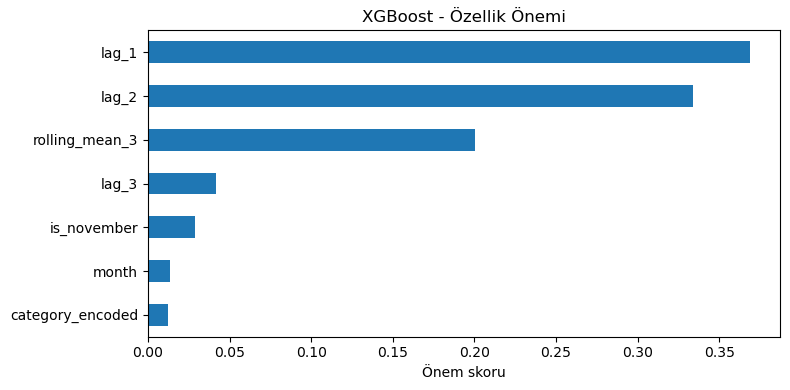

lag_1               0.369
lag_2               0.334
rolling_mean_3      0.201
lag_3               0.042
is_november         0.029
month               0.014
category_encoded    0.012
dtype: float32


In [17]:
import matplotlib.pyplot as plt

onem = pd.Series(best_xgb_model.feature_importances_, index=ozellikler).sort_values()

onem.plot(kind='barh', figsize=(8, 4), title='XGBoost - Özellik Önemi')
plt.xlabel('Önem skoru')
plt.tight_layout()
plt.show()

print(onem.sort_values(ascending=False).round(3))

## 11. Fazla Tahmine Yönelik Denemeler
- **XGBoost (fark):** hedef `sales_qty - lag_1`, tahmine `lag_1` eklendi. Parametreler seviye hedefi için bulunanlar, bu hedef için ayrıca ayarlanmadı.
- **Ridge:** doğrusal model, yalnızca lag özellikleriyle.

**Sonuç:** Naive'i ikisi de geçemedi (WAPE: Naive %15.9, fark yöntemi %20.3, Ridge %23.4). Ridge de toplamda fazla tahmin etti (34.134), yani sorun yalnızca ağaç modellerine özgü değil.

In [18]:
from sklearn.linear_model import Ridge
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

y_train_fark = y_train - X_train['lag_1']
xgb_fark = xgb.XGBRegressor(random_state=42, **xgb_grid.best_params_)
xgb_fark.fit(X_train, y_train_fark)
y_pred_fark = xgb_fark.predict(X_test) + X_test['lag_1']

dogrusal_ozellikler = ['lag_1', 'lag_2', 'lag_3', 'rolling_mean_3']
ridge = make_pipeline(StandardScaler(), Ridge(alpha=1.0))
ridge.fit(X_train[dogrusal_ozellikler], y_train)
y_pred_ridge = ridge.predict(X_test[dogrusal_ozellikler]).clip(min=0)

tahminler2 = {
    'Naive (lag_1)': X_test['lag_1'],
    'XGBoost': y_pred_xgb,
    'XGBoost (fark)': y_pred_fark,
    'Ridge': y_pred_ridge,
}
sonuc2 = []
for isim, tahmin in tahminler2.items():
    sonuc2.append({'Model': isim,
                   'MAE': mean_absolute_error(y_test, tahmin),
                   'RMSE': np.sqrt(mean_squared_error(y_test, tahmin)),
                   'WAPE %': np.abs(y_test - tahmin).sum() / y_test.sum() * 100,
                   'Toplam tahmin': int(np.sum(tahmin))})
pd.DataFrame(sonuc2).sort_values('WAPE %').round(2).reset_index(drop=True)

,Model,MAE,RMSE,WAPE %,Toplam tahmin
0,Naive (lag_1),15.69,31.20,15.89,29954
1,XGBoost (fark),20.01,42.90,20.28,31899
2,Ridge,23.05,44.79,23.36,34134
3,XGBoost,25.12,48.23,25.46,33351


## 12. Kategori Büyüklüğüne Göre Değerlendirme
Kategoriler eğitim dönemi toplam satışına göre üç gruba (Büyük / Orta / Küçük) ayrıldı ve yedi yöntemin tamamı her grupta WAPE ile karşılaştırıldı.

**Sonuç:** Naive, yedi yöntem arasında üç grupta da en düşük WAPE'yi verdi (Büyük %13.6, Orta %30.8, Küçük %53.7). Fark Büyük grupta belirgin (en yakın rakip 3 aylık ortalama, %18.0). Orta grupta çok küçük (en yakın rakip XGBoost fark yöntemi, %32.7); bu fark küçük olduğu için tesadüf olabilir. Büyük 25 kategori test satışlarının yaklaşık %89'unu oluşturduğundan genel sonucu onlar belirliyor. Küçük kategorilerde toplam hacim çok düşük (454 adet), yüzdeler tek başına güvenilir değil.

In [19]:
buyukluk = train.groupby('product_category_name')['sales_qty'].sum()
gruplar = pd.qcut(buyukluk, q=3, labels=['Küçük', 'Orta', 'Büyük'])

t = test[['product_category_name', 'sales_qty']].copy()
t['grup'] = t['product_category_name'].map(gruplar)
t['Naive'] = X_test['lag_1'].values
t['XGBoost (fark)'] = np.array(y_pred_fark)
t['XGBoost'] = y_pred_xgb

satirlar = []
for g in ['Büyük', 'Orta', 'Küçük']:
    a = t[t['grup'] == g]
    satir = {'Grup': g, 'Kategori sayısı': a['product_category_name'].nunique(),
             'Gerçek toplam': int(a['sales_qty'].sum())}
    for m in ['Naive', 'XGBoost (fark)', 'XGBoost']:
        satir[f'WAPE {m}'] = round((a['sales_qty'] - a[m]).abs().sum() / a['sales_qty'].sum() * 100, 1)
    satirlar.append(satir)
pd.DataFrame(satirlar)

,Grup,Kategori sayısı,Gerçek toplam,WAPE Naive,WAPE XGBoost (fark),WAPE XGBoost
0,Büyük,25,25916,13.6,18.1,23.2
1,Orta,24,2843,30.8,32.7,35.2
2,Küçük,25,454,53.7,68.7,95.4


In [20]:
t = test[['product_category_name', 'sales_qty']].copy()
t['grup'] = t['product_category_name'].map(gruplar).astype(str)

tum_tahminler = {
    'Naive (lag_1)': X_test['lag_1'],
    '3 Aylık Ortalama': X_test['rolling_mean_3'],
    'Random Forest': y_pred_rf,
    'XGBoost': y_pred_xgb,
    'LightGBM': y_pred_lgb,
    'XGBoost (fark)': y_pred_fark,
    'Ridge': y_pred_ridge,
}

for isim, tahmin in tum_tahminler.items():
    t[isim] = np.clip(np.array(tahmin), 0, None)

sonuc = []
for g in ['Büyük', 'Orta', 'Küçük']:
    a = t[t['grup'] == g]
    satir = {'Grup': g, 'Gerçek toplam': int(a['sales_qty'].sum())}
    for isim in tum_tahminler:
        satir[isim] = round((a['sales_qty'] - a[isim]).abs().sum() / a['sales_qty'].sum() * 100, 1)
    sonuc.append(satir)

pd.DataFrame(sonuc)

,Grup,Gerçek toplam,Naive (lag_1),3 Aylık Ortalama,Random Forest,XGBoost,LightGBM,XGBoost (fark),Ridge
0,Büyük,25916,13.6,18.0,24.3,23.2,26.0,18.1,20.0
1,Orta,2843,30.8,33.0,38.1,35.2,34.1,32.7,37.7
2,Küçük,454,53.7,61.3,69.7,95.4,80.9,68.7,125.8


## 13. Walk-Forward (Rolling-Origin) Değerlendirme
Tek bir 4 aylık test penceresi sonucun o döneme özgü olup olmadığını göstermez. 2018-03 → 2018-08 arasındaki her ay için model yalnızca o aydan önceki verilerle eğitildi ve o ay tahmin edildi (6 ayrı test). XGBoost için daha önce bulunan en iyi parametreler sabit kullanıldı.

**Sonuç:** Naive 6 ayın 5'inde daha düşük WAPE verdi (ortalama %16.9, XGBoost %22.0). XGBoost'un tek galibiyeti 2018-03'te, farkı 0.7 puan.

**Sınırlılıklar:** Altı ayın hepsi yatay bir dönemde (aylık toplam yaklaşık 7.000-8.200); bu, "tek pencere değil" demek için yeterli ama "her rejimde" demek için yetersiz. Sabit parametreler, ilk test aylarını da içeren veride seçildi (XGBoost lehine hafif iyimserlik). İlk test ayında eğitim seti en küçüktü.

In [21]:
aylar_test = pd.date_range('2018-03-01', '2018-08-01', freq='MS')

satirlar = []
for ay in aylar_test:
    tr = df_model[df_model['order_month'] < ay]
    te = df_model[df_model['order_month'] == ay]

    model = xgb.XGBRegressor(random_state=42, **xgb_grid.best_params_)
    model.fit(tr[ozellikler], tr['sales_qty'])
    tahmin_xgb = model.predict(te[ozellikler])

    gercek = te['sales_qty']
    wape_naive = np.abs(gercek - te['lag_1']).sum() / gercek.sum() * 100
    wape_xgb = np.abs(gercek - tahmin_xgb).sum() / gercek.sum() * 100

    satirlar.append({'Test ayı': ay.strftime('%Y-%m'),
                     'Eğitim satırı': len(tr),
                     'WAPE Naive': round(wape_naive, 1),
                     'WAPE XGBoost': round(wape_xgb, 1)})

rolling = pd.DataFrame(satirlar)
rolling['Kazanan'] = np.where(rolling['WAPE Naive'] <= rolling['WAPE XGBoost'], 'Naive', 'XGBoost')
print(rolling)
print("\nOrtalama WAPE ->", "Naive:", round(rolling['WAPE Naive'].mean(), 1),
      "| XGBoost:", round(rolling['WAPE XGBoost'].mean(), 1))

  Test ayı  Eğitim satırı  WAPE Naive  WAPE XGBoost  Kazanan
0  2018-03            814        18.8          18.1  XGBoost
1  2018-04            888        18.9          21.1    Naive
2  2018-05            962        15.1          24.8    Naive
3  2018-06           1036        20.5          30.0    Naive
4  2018-07           1110        14.1          18.5    Naive
5  2018-08           1184        14.0          19.8    Naive

Ortalama WAPE -> Naive: 16.9 | XGBoost: 22.0


## 14. Naive'in Aylık Performansı ve Trend Kontrolü
Tüm modelleme verisinde (2017-04 → 2018-08) Naive'in aylık WAPE'si hesaplandı.

**Bulgu:** Durağan dönemde (2018-03 → 2018-08) %14-20, satışın sıçradığı aylarda belirgin biçimde kötü: 2017-11 %39.4, 2017-12 %43.0, 2018-01 %34.4. Yani Naive üstünlüğü durağan bir dönemde elde edildi; talep sıçramalarında geçerli olması beklenmemeli.

`(satış - lag_1)` ortalaması eğitim döneminde +5.18, test döneminde -2.5: eğitim verisinde satışlar ortalama artıyordu, test döneminde artmıyordu. Bu, ML modellerinin test döneminde fazla tahmin etmesiyle tutarlı bir göstergedir (nedensellik kanıtı değil).

In [22]:
d = df_model.copy()
d['abs_err'] = (d['sales_qty'] - d['lag_1']).abs()

aylik = d.groupby('order_month').agg(gercek=('sales_qty', 'sum'),
                                     hata=('abs_err', 'sum'))
aylik['WAPE Naive %'] = (aylik['hata'] / aylik['gercek'] * 100).round(1)
print(aylik)

print("\nOrtalama (satış - lag_1), kategori-ay başına")
print("Eğitim:", round((y_train - X_train['lag_1']).mean(), 2))
print("Test  :", round((y_test - X_test['lag_1']).mean(), 2))

             gercek    hata  WAPE Naive %
order_month                              
2017-04-01     2660   627.0          23.6
2017-05-01     4106  1530.0          37.3
2017-06-01     3571   745.0          20.9
2017-07-01     4493  1258.0          28.0
2017-08-01     4882   905.0          18.5
2017-09-01     4815  1043.0          21.7
2017-10-01     5300   837.0          15.8
2017-11-01     8626  3400.0          39.4
2017-12-01     6300  2712.0          43.0
2018-01-01     8173  2809.0          34.4
2018-02-01     7597  1906.0          25.1
2018-03-01     8195  1538.0          18.8
2018-04-01     7957  1506.0          18.9
2018-05-01     7898  1191.0          15.1
2018-06-01     7060  1450.0          20.5
2018-07-01     7039   995.0          14.1
2018-08-01     7216  1007.0          14.0

Ortalama (satış - lag_1), kategori-ay başına
Eğitim: 5.18
Test  : -2.5


## 15. Power BI için Çıktı Tablosu
Yedi yöntemin (2 baseline, RF, XGBoost, LightGBM, XGBoost fark yöntemi, Ridge) test dönemi tahminleri ve kategori büyüklüğü grubu tek tabloda toplandı. Negatif tahminler 0'a çekildi. Tablo ve aylık gerçek satışlar `olist_forecast.xlsx` dosyasına yazıldı; Power BI dashboard'u için veri kaynağı olarak hazırlandı.

In [23]:
# ---- Extra sheets for Power BI (run AFTER the export cell) ----
import pandas as pd

# 1) Walk-forward results (from the `rolling` table)
walk_forward = rolling.rename(columns={
    'Test ayı': 'test_month',
    'Eğitim satırı': 'train_rows',
    'WAPE Naive': 'wape_naive',
    'WAPE XGBoost': 'wape_xgboost',
    'Kazanan': 'winner',
}).copy()
walk_forward['test_month'] = pd.to_datetime(walk_forward['test_month'] + '-01').dt.date
# WAPE was in percent points (16.9); store as a fraction (0.169) so Power BI formats it as %
walk_forward[['wape_naive', 'wape_xgboost']] = walk_forward[['wape_naive', 'wape_xgboost']] / 100

# 2) XGBoost feature importance
feature_importance = (
    pd.Series(best_xgb_model.feature_importances_, index=ozellikler)
    .sort_values(ascending=False)
    .rename_axis('feature')
    .reset_index(name='importance')
)
feature_importance['importance'] = feature_importance['importance'].astype(float).round(4)

# 3) Append both sheets to the existing workbook
with pd.ExcelWriter('olist_forecast.xlsx', mode='a', engine='openpyxl',
                    if_sheet_exists='replace') as yazici:
    walk_forward.to_excel(yazici, sheet_name='walk_forward', index=False)
    feature_importance.to_excel(yazici, sheet_name='feature_importance', index=False)

print(walk_forward)
print(feature_importance)

   test_month  train_rows  wape_naive  wape_xgboost   winner
0  2018-03-01         814       0.188         0.181  XGBoost
1  2018-04-01         888       0.189         0.211    Naive
2  2018-05-01         962       0.151         0.248    Naive
3  2018-06-01        1036       0.205         0.300    Naive
4  2018-07-01        1110       0.141         0.185    Naive
5  2018-08-01        1184       0.140         0.198    Naive
            feature  importance
0             lag_1      0.3688
1             lag_2      0.3341
2    rolling_mean_3      0.2005
3             lag_3      0.0419
4       is_november      0.0286
5             month      0.0136
6  category_encoded      0.0125


## Sonuç ve Değerlendirme
**Bulgular:** Naive, test döneminde (WAPE %15.9) yedi yöntemin hepsinden iyi çıktı ve üç kategori grubunun hepsinde önde. 6 aylık walk-forward testte 5 ayı kazandı (ortalama %16.9 vs XGBoost %22.0). Ağaç modelleri (RF, XGBoost, LightGBM) toplamda %14-16, Ridge ise %17 fazla tahmin etti; XGBoost fark yöntemi bu sapmayı %9'a indirdi. Ancak test ve walk-forward dönemleri yatay bir dönem; Naive'in WAPE'si satışın sıçradığı aylarda %34-43'e çıkıyor.

**İş açısından:** Aylık talep tahmini stok ve sipariş planlamasında kullanılabilir. Durağan dönemlerde "geçen ayın satışı" yaklaşık %16 hata ile güçlü ve ucuz bir başlangıç; ML bunu geçemedi. Talep sıçramalarında (Black Friday gibi) bu kural yeterli değil, ayrı bir yaklaşım gerekir.

**Sınırlılıklar:** 20 aylık veri; mevsimsellik tek yıldan öğrenildi. Test dönemi yatay ve Kasım içermiyor. Tahminler bir ay ilerisi için. Walk-forward yalnızca XGBoost için, sabit parametrelerle yapıldı. XGBoost fark yöntemi için parametreler ayrıca ayarlanmadı. Fiyat, kampanya gibi dış değişkenler yok. Fazla tahmin ve özellik önemi yorumları hipotezdir.

**Sonraki adımlar:** Birden fazla Kasım içeren daha uzun tarihçe, gecikmeli fiyat/kargo özellikleri, tüm modeller için walk-forward, sıçrama aylarını ayrıca değerlendirmek.